In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
df = pd.read_csv('apple_stock_data.csv', header=[0, 1], index_col=0, parse_dates=True)
df.index.name = 'Date'
df.columns.names = ['Num', 'Ticker']
df = df.stack(level='Ticker').reset_index()
df = df[['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume']]
df.head()

Num,Date,Ticker,Open,High,Low,Close,Volume
0,2021-01-04,A,114.467823,115.574577,112.706630,114.179100,2030700.0
1,2021-01-04,AAPL,129.622521,129.709890,123.059845,125.632492,143301900.0
2,2021-01-04,ABBV,86.159128,86.295785,83.490269,84.736275,9523400.0
3,2021-01-04,ABNB,150.990005,151.005005,137.000000,139.149994,6409900.0
4,2021-01-04,ABT,98.245211,98.891031,96.209090,97.868484,6192000.0


Hypothesis Testing 1

H0 = The average Trading volume on down days is equal to or less than average trading volume on up days.

Ha = The average trading volume is signifcantly higher on down days compared to up days

3.02461560866332e-08
Reject the null hypothesis


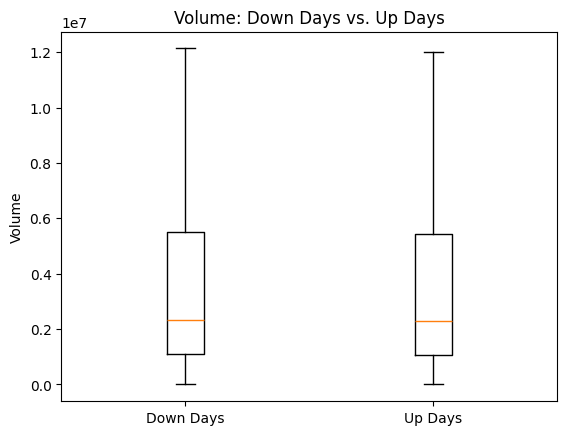

In [31]:
df['Day_Type'] = df.apply(lambda x: 'Down Day' if x['Close']<x['Open'] else 'Up Day', axis = 1)
vol_down = df[df['Day_Type'] == 'Down Day']['Volume'].dropna()
vol_up = df[df['Day_Type'] == 'Up Day']['Volume'].dropna()

u_stat, p_value = stats.mannwhitneyu(vol_down, vol_up, alternative='greater')
print(p_value)
if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis.")
plt.boxplot([vol_down, vol_up], tick_labels=['Down Days', 'Up Days'], showfliers=False)
plt.title("Volume: Down Days vs. Up Days")
plt.ylabel("Volume")
plt.show()